In [1465]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


class Neural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        
        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.sigmoid(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat
    
    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))
    
    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)
    
    def relu(self, z):
        return np.maximum(0, z)
    
    def reluPrime(self,z):
        return 1 * (z > 0)

    def costFunctionPrimeRelu(self, X, y):
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.reluPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def forwardRelu(self,X):
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.relu(self.z3)
        return yHat

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J

    def costFunctionRelu(self, X,y):
        self.yHat=self.forwardRelu(X)
        J=0.5*sum((y-self.yHat)**2)
        return J
    
    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.sigmoidPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2


In [1466]:
X=np.array(([3,5],[5,1],[10,1]),dtype=float)
y=np.array(([75],[80],[93]),dtype=float)

In [1467]:
X


array([[ 3.,  5.],
       [ 5.,  1.],
       [10.,  1.]])

In [1468]:
y

array([[75.],
       [80.],
       [93.]])

In [1469]:
X=X/np.amax(X,axis=0)
y=y/100

In [1470]:
X,y


(array([[0.3, 1. ],
        [0.5, 0.2],
        [1. , 0.2]]),
 array([[0.75],
        [0.8 ],
        [0.93]]))

In [1471]:
NN=Neural_Network()

In [1472]:
yH=NN.forward(X)

In [1473]:
yH

array([[0.64976125],
       [0.63431128],
       [0.65205293]])

In [1474]:
y

array([[0.75],
       [0.8 ],
       [0.93]])

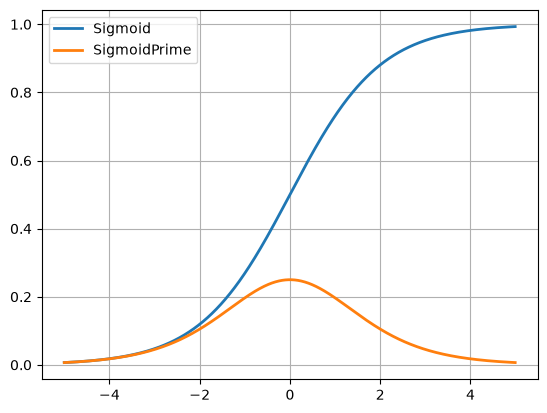

In [1475]:
testValues=np.arange(-5,5,0.01)
plt.plot(testValues,NN.sigmoid(testValues),linewidth=2)
plt.plot(testValues, NN.sigmoidPrime(testValues),linewidth=2)
plt.grid(1)
plt.legend(['Sigmoid','SigmoidPrime'])


In [1476]:
NN=Neural_Network()

In [1477]:
cost1=NN.costFunction(X,y)

In [1478]:
cost1

array([0.01666417])

In [1479]:
dJdW1,dJdW2=NN.costFunctionPrime(X,y)

In [1480]:
dJdW1

array([[-0.00381547, -0.00662842, -0.00374065],
       [-0.00115308, -0.00201466, -0.00114279]])

In [1481]:
dJdW2

array([[-0.03161116],
       [-0.02946265],
       [-0.03088531]])

In [1482]:
scalar= 3
NN.W1 = NN.W1+scalar*dJdW1
NN.W2 = NN.W2+scalar*dJdW2
cost2 = NN.costFunction(X,y)
print (cost1,cost2)

[0.01666417] [0.02764277]


In [1483]:
scalar= 3 #this is our alpha
NN.W1 = NN.W1-scalar*dJdW1
NN.W2 = NN.W2-scalar*dJdW2
cost3 = NN.costFunction(X,y)
print (cost2,cost3)

[0.02764277] [0.01666417]


In [1484]:
# NN.W1 = NN.W1 + scalar*(NN.yHat-NN.a3)*NN.sigmoidPrime(NN.z3)*array([NN.X[0,0], NN.X[0,1], NN.X[0,2]],[NN.X[1,0], NN.X[1,1], NN.X[1,2]])
# NN.W1

[[0.78219368 0.66168335 0.77433774]
 [0.50742069 0.06041632 0.241417  ]] [[0.47201518]
 [0.7645955 ]
 [0.45198027]]


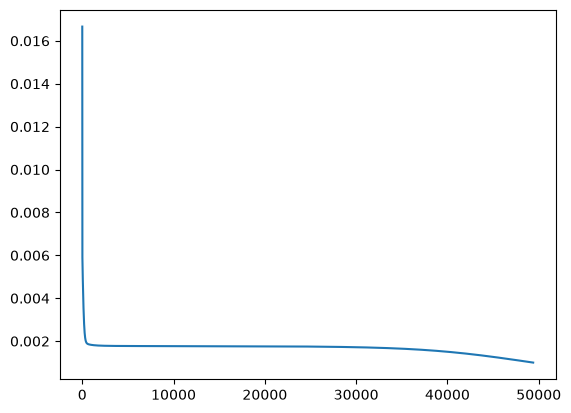

In [1485]:
def minimize(alpha, accuracyPoop):
    W1_init = NN.W1
    W2_init = NN.W2
    print(W1_init,W2_init)
    cost = NN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = NN.costFunctionPrime(X, y)

        NN.W1 = NN.W1-alpha*dJdW1
        NN.W2 = NN.W2-alpha*dJdW2

        cost = NN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arr = (minimize(2, .001))

# print(cost_arr)
plt.plot(cost_arr)

In [1486]:
y

array([[0.75],
       [0.8 ],
       [0.93]])

In [1487]:
NN.forward(X)

array([[0.74426091],
       [0.83214019],
       [0.89943848]])

In [1488]:

class ReluNeural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)


[[0.96805224 0.1188727  0.07051317]
 [0.77524623 0.58327772 0.03231917]] [[0.03407958]
 [0.34174413]
 [0.16719348]]


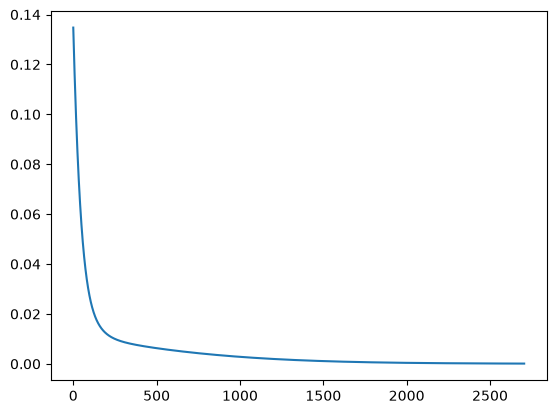

In [1489]:
ReluNN = ReluNeural_Network()

def minimizeRelu(alpha, accuracyPoop):
    W1_init = ReluNN.W1
    W2_init = ReluNN.W2
    print(W1_init,W2_init)
    cost = ReluNN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = ReluNN.costFunctionPrime(X, y)

        ReluNN.W1 = ReluNN.W1-alpha*dJdW1
        ReluNN.W2 = ReluNN.W2-alpha*dJdW2

        cost = ReluNN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arrRelu = (minimizeRelu(.05, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu)

In [1490]:
ReluNN.forward(X)-y

array([[ 0.00842491],
       [-0.01116747],
       [-0.00205749]])

In [1491]:
class ReluNeural_Network_Extra(object):
    def __init__(self, size):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        self.hiddenLayer_2_Size = size

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.hiddenLayer_2_Size)
        self.W3=np.random.rand(self.hiddenLayer_2_Size,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        self.a3 = self.relu(self.z3)
        self.z4 = np.dot(self.a3, self.W3)
        yHat = self.sigmoid(self.z4)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta4 = np.multiply(-(y-self.yHat), self.sigmoidPrime(self.z4))
        dJdW3=np.dot(self.a3.T, delta4)
        delta3 = np.dot(delta4, self.W3.T)* self.sigmoidPrime(self.z3)
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2, dJdW3

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)



[[0.27198537 0.09016536 0.80384818]
 [0.98865465 0.73349187 0.97513372]] [[0.88054974 0.65911308 0.78181094]
 [0.52982477 0.12932834 0.41309408]
 [0.70281861 0.44790187 0.31083044]]


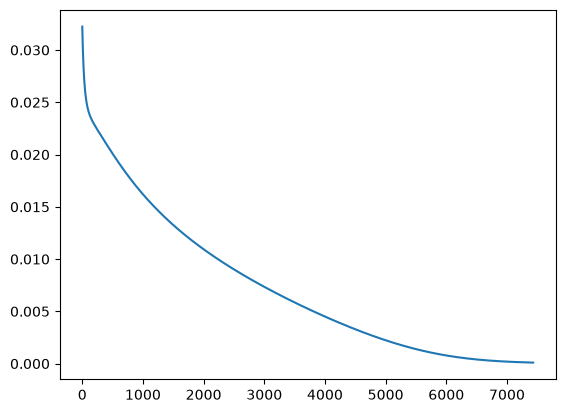

In [1492]:
ReluNN_Extra_3 = ReluNeural_Network_Extra(3)

def minimizeRelu_Extra(alpha, accuracyPoop):
    W1_init = ReluNN_Extra_3.W1
    W2_init = ReluNN_Extra_3.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_3.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_3.costFunctionPrime(X, y)

        ReluNN_Extra_3.W1 = ReluNN_Extra_3.W1 - alpha * dJdW1
        ReluNN_Extra_3.W2 = ReluNN_Extra_3.W2 - alpha * dJdW2
        ReluNN_Extra_3.W3 = ReluNN_Extra_3.W3 - alpha * dJdW3

        cost = ReluNN_Extra_3.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra = (minimizeRelu_Extra(.1, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra)


In [1493]:
ReluNN_Extra_3.forward(X) - y

array([[ 0.00896124],
       [-0.01078404],
       [-0.00177355]])

[[0.23644419 0.63650945 0.99722142]
 [0.84710519 0.82546446 0.52954609]] [[0.34922103 0.48990307 0.45969781 0.2763437  0.74037023 0.62232324
  0.39258958 0.52064923 0.53794595 0.41142067]
 [0.84036728 0.38717792 0.70113742 0.80385424 0.51471472 0.92463602
  0.68742009 0.22477785 0.70780733 0.12878505]
 [0.32620569 0.8952947  0.53248012 0.71429042 0.53080985 0.85287106
  0.22345402 0.85108558 0.29742432 0.57473888]]


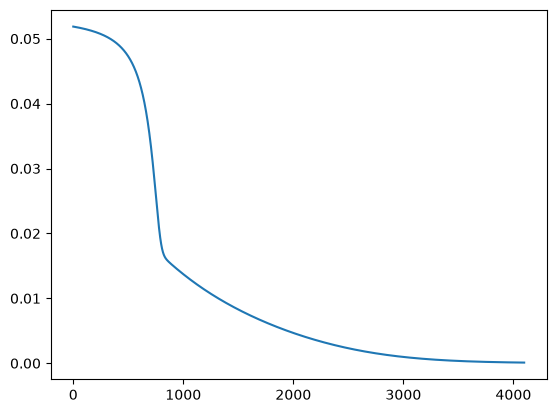

In [1494]:
ReluNN_Extra_10 = ReluNeural_Network_Extra(10)

def minimizeRelu_Extra(alpha, accuracyPoop):
    W1_init = ReluNN_Extra_10.W1
    W2_init = ReluNN_Extra_10.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_10.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_10.costFunctionPrime(X, y)

        ReluNN_Extra_10.W1 = ReluNN_Extra_10.W1 - alpha * dJdW1
        ReluNN_Extra_10.W2 = ReluNN_Extra_10.W2 - alpha * dJdW2
        ReluNN_Extra_10.W3 = ReluNN_Extra_10.W3 - alpha * dJdW3

        cost = ReluNN_Extra_10.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra_10= (minimizeRelu_Extra(.1, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra_10)



In [1495]:
ReluNN_Extra_10.forward(X) - y

array([[ 0.00863997],
       [-0.01101191],
       [-0.00194204]])

In [ ]:
plt.plot(cost_arr, label = "sigmoid")
plt.plot(cost_arrRelu, label = "relu")
plt.plot(cost_arrRelu_Extra, label = "extra hidden layer size 3")
plt.plot(cost_arrRelu_Extra_10, label = "extra hidden layer size 10")
plt.legend()
plt.show()